# **Libraries**
---
The libraries used throughout the workflow are imported: utilities, visualization, data handling, synthetic data generation, decision tree modeling, hyperparameter search, and evaluation metrics.

In [2]:
# Utils
# ==============================================================================
import warnings

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Data
# ==============================================================================
import pandas as pd
from sklearn.datasets import make_classification

# Model
# ==============================================================================
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Metrics
# ==============================================================================
from sklearn.metrics import accuracy_score

# **Info**
---

**@By**: Steven Bernal

**@Nickname**: Kaiziferr

**@Git**: https://github.com/Kaiziferr

# **Config**
---
The seaborn `darkgrid` style is applied to the plots, warnings are disabled, a color palette is defined from the tab10 palette, and the random seed is set to `12354`. The seed is used in data generation, in the data split, and in the model, so the results can be reproduced.

In [3]:
sns.set(style="darkgrid")
warnings.simplefilter("ignore")
paleta = sns.color_palette("tab10").as_hex()
random_seed = 12354

# **Context**
---

A synthetic dataset was chosen for this classification problem because it provides a controlled and educational environment, specifically designed to explain the **pre-pruning** process in decision trees.

Working with real-world datasets usually requires a significant amount of effort in preprocessing tasks such as data cleaning, handling missing values, correcting inconsistencies, and transforming variables. While these steps are essential in any data science workflow, they are outside the scope of this discussion.

# **Goals**
---

- Implement pre-pruning in a decision tree applied to a classification problem using synthetic data.

# **Data**
---

- The dataset is generated with `1,000` samples and 10 features. Of these, 6 features are informative and 2 are redundant. No duplicated features are included.
- The task is a binary classification problem with two classes. Each class is distributed into two clusters within the feature space.
- A label noise rate of 0.08 is introduced, meaning that 8% of the labels are randomly flipped. The class separation is set to 0.8, and the classes are balanced.
- A random seed is used to ensure the reproducibility of the dataset.

In [4]:
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    weights=[0.5, 0.5],
    flip_y=0.08,
    class_sep=0.8,
    random_state=random_seed
)

The feature matrix is converted into a pandas DataFrame, and each column is named A0, A1, …, A9. This makes the features easier to identify in the following steps.

In [5]:
X = pd.DataFrame(X, columns=[f'A{i}'for i in range(X.shape[1])])

# **Model**
---

The dataset is split into training and test sets using a random partition. 20% of the samples are assigned to the test set, while the remaining 80% are used for training. This results in 800 training samples and 200 test samples.

The split preserves the original structure of the input features and their corresponding labels. A random seed is used to ensure the reproducibility of the partition.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=random_seed
)

A parameter dictionary was defined to configure a decision tree model. The max_depth, min_samples_split, and min_samples_leaf hyperparameters apply **pre-pruning**, since they stop tree growth before the tree fully fits the training data:

- The splitting criterion was set using the options gini, entropy, and log_loss, which determine the metric used to evaluate the quality of splits at each node.
- The split strategy was defined using best and random, controlling whether the optimal split is selected or a random one is chosen.
- The maximum depth of the tree (max_depth) was configured with the values 3, 5, 10, 20, and 30, constraining the model's growth at different levels of complexity. The grid does not include None, so every evaluated combination has a depth limit.
- The minimum number of samples required to split an internal node (min_samples_split) was set to 2, 5, 10, and 20, defining the threshold at which a node is eligible for further partitioning.
- The minimum number of samples allowed in a leaf node (min_samples_leaf) was set to 1, 2, 4, and 8, controlling the smallest possible size of terminal nodes.
- The number of features considered at each split (max_features) was defined using None, sqrt, log2, 0.5, and 0.75, limiting or adjusting the subset of variables used for each decision split.

The grid produces `2,400` combinations (3 × 2 × 5 × 4 × 4 × 5).

In [7]:
dic_params = {
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [3, 5, 10, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [None, "sqrt", "log2", 0.5, 0.75]
}

- A classification model based on a decision tree was defined using DecisionTreeClassifier.
- A random seed was set through random_state to ensure the reproducibility of the model across different runs.

In [8]:
model_classifier_prepruning_v1 = DecisionTreeClassifier(random_state=random_seed)

Hyperparameter tuning was configured using cross-validated grid search via GridSearchCV:

- The previously initialized decision tree model was used as the base estimator. A parameter grid (param_grid) was defined to explore different model configurations.
- Accuracy was selected as the evaluation metric. Ten-fold cross-validation (cv=10) was applied, assessing model performance across different subsets of the training data. With 2,400 combinations and 10 folds, the search performs 24,000 model fits.
- The refit=True option was enabled to retrain the model using the best combination of hyperparameters found during the search. Additionally, return_train_score=True was activated to store training performance metrics during the search process.
- Finally, the model was fitted using the training data X_train and y_train.

In [9]:
model_classifier_prepruning_v1 = GridSearchCV(
    estimator=model_classifier_prepruning_v1,
    param_grid=dic_params,
    scoring='accuracy',
    cv=10,
    refit=True,
    return_train_score = True
)
model_classifier_prepruning_v1.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=DecisionTreeClassifier(random_state=12354),
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [3, 5, 10, 20, 30],
                         'max_features': [None, 'sqrt', 'log2', 0.5, 0.75],
                         'min_samples_leaf': [1, 2, 4, 8],
                         'min_samples_split': [2, 5, 10, 20],
                         'splitter': ['best', 'random']},
             return_train_score=True, scoring='accuracy')

The output confirms the search configuration: a DecisionTreeClassifier with random_state=12354 as the base estimator, the grid of six hyperparameters, accuracy as the metric, ten folds, and the storage of training scores. The best hyperparameters found are retrieved next.

In [10]:
model_classifier_prepruning_v1.best_params_

{'criterion': 'gini',
 'max_depth': 20,
 'max_features': None,
 'min_samples_leaf': 4,
 'min_samples_split': 20,
 'splitter': 'best'}

- The best hyperparameters were obtained from the cross-validated grid search process. The resulting best_params_ are as follows:
  - criterion: gini
  - max_depth: 20
  - max_features: None
  - min_samples_leaf: 4
  - min_samples_split: 20
  - splitter: best
- From a pre-pruning perspective, the selected configuration requires at least `20 samples to split a node` and `4 samples in each leaf`. With max_features=None, all 10 features are considered at each split, and with splitter=best, the best available split is always selected.

The position of this combination within the search results is retrieved next.

In [11]:
model_classifier_prepruning_v1.best_index_

np.int64(502)

The best_index_ value is `502`. It is the position of the best combination within cv_results_, which contains one row for each of the 2,400 evaluated combinations. This index is used in the next cell to extract the scores of that combination.

The cross-validation results are converted into a DataFrame. For the best combination, the mean validation score (mean_test_score), the mean training score (mean_train_score), its position in the ranking (rank_test_score), and its hyperparameter values are extracted.

In [12]:
scores = pd.DataFrame(model_classifier_prepruning_v1.cv_results_)
scores.loc[
    model_classifier_prepruning_v1.best_index_,
    ['mean_test_score', 'mean_train_score', 'rank_test_score']
    + [c for c in scores.columns if c.startswith('param_')]
]

,502
mean_test_score,0.8375
mean_train_score,0.907917
rank_test_score,1
param_criterion,gini
param_max_depth,20
param_max_features,None
param_min_samples_leaf,4
param_min_samples_split,20
param_splitter,best


- The mean_train_score is `0.907917`, representing the average model performance on the training subsets within each cross-validation fold.
- The mean_test_score is `0.8375`, corresponding to the average performance on the validation subsets in each fold.
- The difference between these two values is 7.04 percentage points, about 7.8% relative to the training score. This indicates a decrease in performance when moving from the data used for fitting to unseen validation data within each fold.
- Overall, the model performs better on the data used for fitting than on the validation data, although the gap is not large. The rank_test_score of 1 confirms that this combination obtained the highest mean validation accuracy in the grid.

The best model (best_estimator_), already retrained on the full training set, is extracted. The actual depth of the tree and its number of terminal nodes (leaves) are then retrieved.

In [13]:
model_classifier_prepruning_v1_best = model_classifier_prepruning_v1.best_estimator_
print(f"Tree depth: {model_classifier_prepruning_v1_best.get_depth()}")
print(f"Number of terminal nodes: {model_classifier_prepruning_v1_best.get_n_leaves()}")

Tree depth: 12
Number of terminal nodes: 41


There is an important distinction between the max_depth=20 hyperparameter and the actual depth of the trained tree. While the maximum allowed depth was set to 20, get_depth() returns `12`, indicating the depth that the tree actually reached during training. The tree has **41 terminal nodes**.

The tree stopped growing at depth 12 because no additional node splits could be performed while satisfying the remaining constraints. This suggests that max_depth was not an active limiting factor in this case.

It is likely that the exact same tree would have been obtained with max_depth values of 12, 15, 20, or even 30, since tree growth was already constrained by other hyperparameters, such as min_samples_leaf=4 and min_samples_split=20.

The best mean validation score (best_score_), rounded to two decimal places, is printed together with the associated hyperparameter combination.

In [14]:
print(f'The best score: {model_classifier_prepruning_v1.best_score_:,.2f}')
print(f'The best params: {model_classifier_prepruning_v1.best_params_}')

The best score: 0.84
The best params: {'criterion': 'gini', 'max_depth': 20, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 20, 'splitter': 'best'}


The best score is `0.84`, the rounded value of the 0.8375 mean validation accuracy shown in the previous table. The printed hyperparameters match best_params_, so the output briefly confirms the search result.

The best model is used to generate predictions on the test set and on the training set, so that the accuracy on both sets can be compared.

In [16]:
y_predict_prepruning_v1_test = model_classifier_prepruning_v1_best.predict(X_test)
y_predict_prepruning_v1_train = model_classifier_prepruning_v1_best.predict(X_train)

The accuracy of the predictions is calculated on the training set and on the test set.

In [17]:
print(f'Prediction Data Train: {accuracy_score(y_train, y_predict_prepruning_v1_train)}')
print(f'Prediction Data Test: {accuracy_score(y_test, y_predict_prepruning_v1_test)}')

Prediction Data Train: 0.90625
Prediction Data Test: 0.74


The model achieved an accuracy of `0.90625` on the training data, about 90.6%. This indicates that the algorithm captured a large part of the patterns present in the training dataset.

However, when evaluated on the test data, which represents new information not seen during training, the performance dropped to an accuracy of `0.74`, that is, 148 correct predictions out of 200 samples. The difference is 16.6 percentage points.

The test accuracy is also 9.75 points below the mean cross-validation accuracy (0.8375). This suggests that the model fitted the training data too closely, including specific patterns or noise, and therefore does not generalize as well to new data, although it still performs moderately well. With 200 test samples, each correct prediction is worth 0.5 percentage points, so part of the difference may also be due to the data split. This last explanation is a hypothesis and was not verified.

## **Effect of pre-pruning**
---
Validation curves are built from the results already stored in cv_results_, without training new models. For each pre-pruning hyperparameter (max_depth, min_samples_leaf, and min_samples_split), the combinations in which the remaining hyperparameters match the best configuration are selected, so only the analyzed hyperparameter changes.

- **X-axis:** values of the hyperparameter evaluated in the grid.
- **Y-axis:** accuracy, shared by the three panels.
- **Blue line:** mean training accuracy across the ten folds (mean_train_score).
- **Orange line:** mean validation accuracy (mean_test_score). The shaded band shows ± 1 standard deviation across folds.
- **Dashed line:** value selected by GridSearchCV.

The values of each curve and the gap between training and validation are printed below the plot.

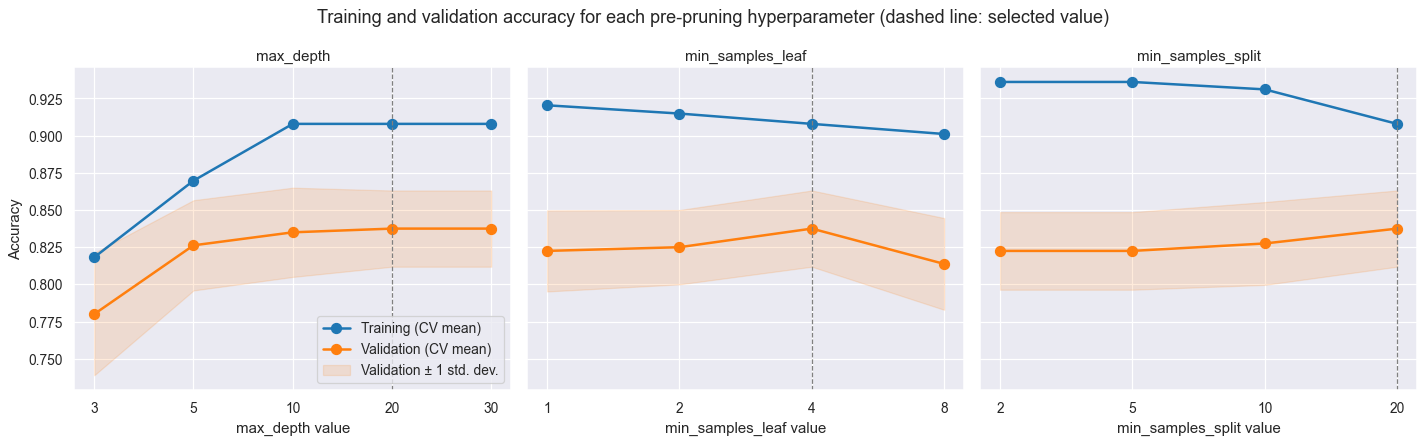

--- max_depth (remaining hyperparameters fixed at the best configuration) ---
 param_max_depth  mean_train_score  mean_test_score  std_test_score    gap
               3            0.8182           0.7800          0.0412 0.0382
               5            0.8697           0.8262          0.0303 0.0435
              10            0.9079           0.8350          0.0300 0.0729
              20            0.9079           0.8375          0.0256 0.0704
              30            0.9079           0.8375          0.0256 0.0704
--- min_samples_leaf (remaining hyperparameters fixed at the best configuration) ---
 param_min_samples_leaf  mean_train_score  mean_test_score  std_test_score    gap
                      1            0.9204           0.8225          0.0273 0.0979
                      2            0.9149           0.8250          0.0250 0.0899
                      4            0.9079           0.8375          0.0256 0.0704
                      8            0.9011           0.8138 

In [ ]:
# Validation curves for the pre-pruning hyperparameters
best = scores.loc[model_classifier_prepruning_v1.best_index_]
param_cols = [c for c in scores.columns if c.startswith('param_')]
hyperparameters = ['max_depth', 'min_samples_leaf', 'min_samples_split']

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, h in zip(axes, hyperparameters):
    # The remaining hyperparameters are fixed at the values of the best configuration
    mask = pd.Series(True, index=scores.index)
    for col in param_cols:
        if col != f'param_{h}':
            mask &= scores[col].astype(str) == str(best[col])
    curve = scores[mask].sort_values(f'param_{h}')
    x = curve[f'param_{h}'].astype(str)

    ax.plot(x, curve['mean_train_score'], marker='o', markersize=8, linewidth=2,
            color=paleta[0], label='Training (CV mean)')
    ax.plot(x, curve['mean_test_score'], marker='o', markersize=8, linewidth=2,
            color=paleta[1], label='Validation (CV mean)')
    ax.fill_between(x, curve['mean_test_score'] - curve['std_test_score'],
                    curve['mean_test_score'] + curve['std_test_score'],
                    color=paleta[1], alpha=0.15, label='Validation ± 1 std. dev.')
    ax.axvline(str(best[f'param_{h}']), color='gray', linestyle='--', linewidth=1)
    ax.set_title(h)
    ax.set_xlabel(f'{h} value')

    print(f'--- {h} (remaining hyperparameters fixed at the best configuration) ---')
    print(curve[[f'param_{h}', 'mean_train_score', 'mean_test_score', 'std_test_score']]
          .assign(gap=curve['mean_train_score'] - curve['mean_test_score'])
          .round(4).to_string(index=False))

axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right')
fig.suptitle('Training and validation accuracy for each pre-pruning hyperparameter '
             '(dashed line: selected value)')
plt.tight_layout()
plt.show()

**max_depth**

- With a maximum depth of 3, the training accuracy is 0.8182 and the validation accuracy is 0.7800. Both values are the lowest in the panel, indicating that such a constrained tree does not capture all the patterns in the data (underfitting).
- At depths of 5 and 10, both scores increase, and validation accuracy reaches 0.8262 and 0.8350. From 10 onward, training accuracy stays at 0.9079 and validation accuracy stays between 0.8350 and 0.8375. The flat curves confirm what was observed with get_depth(): once the limit exceeds the depth that the tree reaches on its own, max_depth no longer has an effect. The values 20 and 30 produce exactly the same scores.
- The gap between training and validation grows from 3.82 points with max_depth=3 to 7.04 points with 20. Greater depth improves validation accuracy, but it also increases overfitting.

**min_samples_leaf**

- Training accuracy decreases steadily as the minimum leaf size increases, from 0.9204 with 1 to 0.9011 with 8. This is the expected effect of pre-pruning, since larger leaves prevent the tree from memorizing individual cases.
- Validation accuracy reaches its maximum at `4` (0.8375). With 8, it drops to 0.8138, the lowest value in the panel. This suggests that restricting leaf size too much starts to remove useful patterns.

**min_samples_split**

- The values 2 and 5 produce the same result (training 0.9361, validation 0.8225), with the largest gap across the three panels: `11.36 points`.
- At 10 and 20, training accuracy decreases to 0.9079 and validation accuracy increases to 0.8375. The gap narrows to 7.04 points.
- The selected value, 20, is the maximum in the grid. These results cannot show whether a larger value would improve validation accuracy, because no larger value was evaluated.

**Variability**

- The standard deviation of validation accuracy across folds ranges from 0.0250 to 0.0412. Several differences between neighboring values, such as 0.8350 versus 0.8375 for max_depth, are much smaller than this variability, so they should not be interpreted as real improvements.

**Conclusion**

The plot shows how pre-pruning works on this data. The min_samples_leaf and min_samples_split constraints reduce training accuracy and the gap with validation accuracy, while max_depth only acts as a limit when it is smaller than the natural depth of the tree.

# **Conclusions**
---
The results show how pre-pruning can be used to control the complexity of a decision tree. The selected configuration (min_samples_leaf=4 and min_samples_split=20) produced a tree with **depth 12 and 41 leaves**, and the validation curves show that these constraints reduced the gap between training and validation within cross-validation.

However, some degree of overfitting remains, since accuracy dropped from `0.906` on the training data to `0.74` on the test data. The pruned tree was not compared with an unconstrained tree in this analysis, so these results cannot quantify how much pre-pruning improves on the default configuration.

# **Info**
---

**@By**: Steven Bernal

**@Nickname**: Kaiziferr

**@Git**: https://github.com/Kaiziferr